In [32]:
import math
import random
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np

# Задача 5.1

In [33]:
def analyze(dist):
    joint = defaultdict(float)
    for x,p in dist.items():
        y2 = x % 2
        y3 = x % 3
        joint[(y2,y3)] += p
    
    marg2 = defaultdict(float)
    marg3 = defaultdict(float)
    
    for (a,b),p in joint.items():
        marg2[a] += p
        marg3[b] += p
    
    indep = all(abs(joint[(a,b)] - marg2[a]*marg3[b]) < 1e-12 for (a,b) in joint)
    E_y2 = sum(a * marg2[a] for a in marg2)
    E_y3 = sum(b * marg3[b] for b in marg3)
    E_y2y3 = sum(a*b*p for (a,b),p in joint.items())
    cov = E_y2y3 - E_y2*E_y3
    
    return indep, joint, marg2, marg3, E_y2, E_y3, cov

In [34]:
print("Uniform:")
dist_uniform = {k: 1/6 for k in range(1,7)}
print(analyze(dist_uniform))

weights = {k: k for k in range(1,7)}
s = sum(weights.values())
dist_prop = {k: weights[k]/s for k in weights}
print("Proportional to k:")
print(analyze(dist_prop))

Uniform:
(True, defaultdict(<class 'float'>, {(1, 1): 0.16666666666666666, (0, 2): 0.16666666666666666, (1, 0): 0.16666666666666666, (0, 1): 0.16666666666666666, (1, 2): 0.16666666666666666, (0, 0): 0.16666666666666666}), defaultdict(<class 'float'>, {1: 0.5, 0: 0.5}), defaultdict(<class 'float'>, {1: 0.3333333333333333, 2: 0.3333333333333333, 0: 0.3333333333333333}), 0.5, 1.0, 0.0)
Proportional to k:
(False, defaultdict(<class 'float'>, {(1, 1): 0.047619047619047616, (0, 2): 0.09523809523809523, (1, 0): 0.14285714285714285, (0, 1): 0.19047619047619047, (1, 2): 0.23809523809523808, (0, 0): 0.2857142857142857}), defaultdict(<class 'float'>, {1: 0.42857142857142855, 0: 0.5714285714285714}), defaultdict(<class 'float'>, {1: 0.23809523809523808, 2: 0.3333333333333333, 0: 0.42857142857142855}), 0.42857142857142855, 0.9047619047619047, 0.13605442176870747)


# Задача 5.2

In [35]:
distX = {i: 1/13 for i in range(0,13)}
distY = {j: 1/14 for j in range(0,14)}
distZ = {3: 9/10, 7: 1/10}

distXY = defaultdict(float)
for x,px in distX.items():
    for y,py in distY.items():
        distXY[x+y] += px*py

distXYZ = defaultdict(float)
for s,ps in distXY.items():
    for z,pz in distZ.items():
        distXYZ[s+z] += ps*pz

print("P(sum=12) =", distXYZ.get(12,0))
most_prob_value, most_prob = max(distXYZ.items(), key=lambda kv: kv[1])
print("Most probable sum:", most_prob_value, "with prob", most_prob)

P(sum=12) = 0.052747252747252754
Most probable sum: 16 with prob 0.06978021978021978


# Задача 5.3

In [36]:
def prop_dist(n):
    s = n*(n+1)//2
    return {i: i/s for i in range(1, n+1)}

distX = prop_dist(13)
distY = prop_dist(12)
distZ = prop_dist(8)

prob = 0.0
for i,px in distX.items():
    for j,py in distY.items():
        for k,pz in distZ.items():
            if i!=j and i!=k and j!=k:
                prob += px*py*pz
print("P(all different) =", prob)

P(all different) = 0.7836479759556683


# Задача 5.4

In [37]:
pmf = {}
for k in range(1,7):
    p = ((6-(k-1))/6)**4 - ((6-k)/6)**4
    pmf[k] = p

E = sum(k*p for k,p in pmf.items())
E2 = sum(k*k*p for k,p in pmf.items())
Var = E2 - E*E
print("Analytic E(min) =", E)
print("Analytic Var(min) =", Var)

joint = {}
for d in range(1,7):
    for m in range(1,7):
        if d < m:
            prob = 0.0
        elif d == m:
            prob = (1/6) * ((7-m)/6)**3
        else:
            total_ge = ((7-m)/6)**3
            all_gt = ((6-m)/6)**3
            prob = (1/6) * (total_ge - all_gt)
        joint[(d,m)] = prob

E_D1min = sum(d*m*p for (d,m),p in joint.items())
cov = E_D1min - 3.5*E
print("Cov(D1, min) =", cov)

Analytic E(min) = 1.755401234567901
Analytic Var(min) = 0.9100788513565008
Cov(D1, min) = 0.5590277777777786


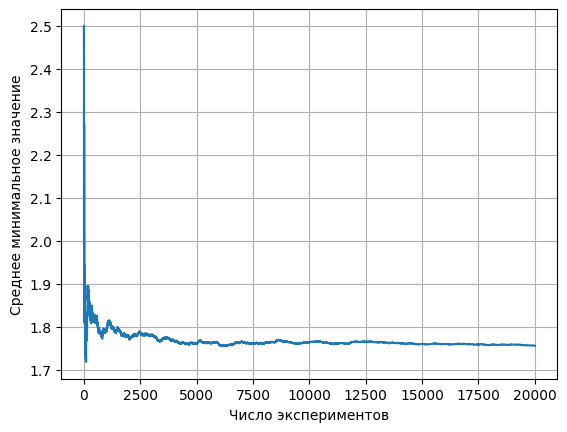

In [38]:
def simulate(n_trials):
    s = 0.0
    means = []
    for i in range(1, n_trials+1):
        rolls = [random.randint(1,6) for _ in range(4)]
        mn = min(rolls)
        s += mn
        means.append(s/i)
    return means

means = simulate(20000)
plt.plot(range(1, len(means)+1), means)
plt.xlabel("Число экспериментов")
plt.ylabel("Среднее минимальное значение")
plt.grid(True)
plt.show()

# Задача 5.5

In [39]:
pmf_max = {}
for k in range(1,7):
    p = (k/6)**4 - ((k-1)/6)**4
    pmf_max[k] = p

Emax = sum(k*p for k,p in pmf_max.items())
Varmax = sum(k*k*p for k,p in pmf_max.items()) - Emax*Emax

print("E(max) =", Emax)
print("Var(max) =", Varmax)

E(max) = 5.244598765432099
Var(max) = 0.910078851356495


# Задача 5.6

In [40]:
E_min = 1.7554012345679013

E_S = 4*3.5 - E_min

print("E(S) =", E_S)

E(S) = 12.244598765432098


# Задача 5.7

In [41]:
pA, pB, pC = 0.4, 0.3, 0.2

E_V = 2*pA + 4*pB + 6*pC
VarV = 4*(pA*(1-pA)) + 16*(pB*(1-pB)) + 36*(pC*(1-pC))

print("E(V) =", E_V)
print("Var(V) =", VarV)

E(V) = 3.2
Var(V) = 10.080000000000002


# Задача 5.8

In [42]:
dist = {i: 1/64 for i in range(1,65)}
probY = defaultdict(float)
for x,p in dist.items():
    probY[abs(x-13.5)] += p

vals = sorted(probY)
cdf = 0.0
Q1Min = None
for v in vals:
    cdf += probY[v]
    if Q1Min is None and cdf >= 0.25:
        Q1Min = v

Q1Max = max(v for v in vals if sum(probY[u] for u in vals if u>=v) >= 0.75)

cdf = 0.0
Q3Min = None
for v in vals:
    cdf += probY[v]
    if Q3Min is None and cdf >= 0.75:
        Q3Min = v

Q3Max = max(v for v in vals if sum(probY[u] for u in vals if u>=v) >= 0.25)

print(Q1Min, Q1Max, Q3Min, Q3Max)

7.5 8.5 34.5 35.5


# Задача 5.9

In [43]:
pX = 42/100
pY = 58/100
pXY = 24/100

p0 = 1 - pX - pY + pXY
p2 = pXY
p1 = 1 - p0 - p2

E_Z = p1*1 + p2*2
E_Z2 = p1*1 + p2*4
Var_Z = E_Z2 - E_Z**2

E_U = 5 * E_Z
Var_U = 5 * Var_Z

E_V = E_Z ** 5
E_V2 = E_Z2 ** 5
Var_V = E_V2 - E_V**2

print("P(Z=0, Z=1, Z=2) =", p0, p1, p2)
print("E(Z) =", E_Z, "E(Z^2) =", E_Z2, "Var(Z) =", Var_Z)
print("E(U) =", E_U, "Var(U) =", Var_U)
print("E(V) =", E_V, "Var(V) =", Var_V)

P(Z=0, Z=1, Z=2) = 0.2400000000000001 0.5199999999999999 0.24
E(Z) = 0.9999999999999999 E(Z^2) = 1.48 Var(Z) = 0.4800000000000002
E(U) = 4.999999999999999 Var(U) = 2.4000000000000012
E(V) = 0.9999999999999994 Var(V) = 6.1008211968


# Задача 5.10

In [44]:
values = [2,5,8,10]
p = 0.25
distS = defaultdict(float)
for a in values:
    for b in values:
        for c in values:
            distS[a+b+c] += p**3

E = sum(s*prob for s,prob in distS.items())

sorted_items = sorted(distS.items())
cdf = 0.0
MedMin = None
for s,prob in sorted_items:
    cdf += prob
    if MedMin is None and cdf >= 0.5:
        MedMin = s

cum = 0.0
MedMax = None
for s,prob in reversed(sorted_items):
    cum += prob
    if MedMax is None and cum >= 0.5:
        MedMax = s

maxp = max(distS.values())
modes = [s for s,prob in distS.items() if prob == maxp]

print("E(S) =", E)
print("MedMin =", MedMin, "MedMax =", MedMax)
print("Modes =", modes)

E(S) = 18.75
MedMin = 18 MedMax = 20
Modes = [20]


# Задача 5.11

In [45]:
muls = [(1.04, 0.1), (1.003, 0.5), (0.99, 0.4)]

Em = sum(m*p for m,p in muls)
Em2 = sum((m**2)*p for m,p in muls)

S0 = 1000
n = 160

E_Sn = S0 * (Em**n)

Var_Sn = (S0**2) * ((Em2**n) - (Em**(2*n)))
std_Sn = Var_Sn**0.5

print("E(S160) =", E_Sn)
print("std(S160) =", std_Sn)

E(S160) = 1271.0205745939686
std(S160) = 230.14205180145913


# Задача 5.12

In [46]:
muA, muB = 0.04, 0.05
sA, sB = 0.05, 0.08
rho = 0.26

wA = (sB**2 - rho*sA*sB) / (sA**2 + sB**2 - 2*rho*sA*sB)
wB = 1 - wA

muP = wA*muA + wB*muB

varP = wA**2*sA**2 + wB**2*sB**2 + 2*wA*wB*rho*sA*sB
sdP = varP**0.5

print("wA, wB =", wA, wB)
print("Expected return =", muP)
print("Std dev =", sdP)

wA, wB = 0.785923753665689 0.214076246334311
Expected return = 0.04214076246334311
Std dev = 0.0467701687013411


# Задача 5.13

In [47]:
mus = np.array([0.01, 0.03, 0.03])
sds = np.array([0.02, 0.06, 0.05])

vars = sds**2
weights = (1/vars) / ( (1/vars).sum() )
expected = (weights * mus).sum()

print("weights =", weights)
print("Expected portfolio return (%) =", expected*100)

weights = [0.78671329 0.08741259 0.12587413]
Expected portfolio return (%) = 1.4265734265734262


# Задача 5.14

In [48]:
# 5.14
wA = 7/8
wB = 1/8
muA, muB = 0.03, 0.02
sA, sB = 0.04, 0.04
rho = 0.3

varP = wA**2*sA**2 + wB**2*sB**2 + 2*wA*wB*rho*sA*sB
sdP = varP**0.5

print("Std dev (%) =", sdP*100)

Std dev (%) = 3.6810324638611926


# Задача 5.15

In [49]:
s1,s2,s3 = 0.8,1.8,0.4

lam = s1**2 + s2**2 + s3**2

p7 = math.exp(-lam) * lam**7 / math.factorial(7)

mode = int(math.floor(lam))
sd = math.sqrt(lam)
skew = 1/sd
excess = 1/lam

print("lambda =", lam)
print("P(X=7) =", p7)
print("mode =", mode, "sd =", sd, "skew =", skew, "excess =", excess)

lambda = 4.04
P(X=7) = 0.06133230863284511
mode = 4 sd = 2.009975124224178 skew = 0.49751859510499463 excess = 0.24752475247524752
